# 🛍️ Lab 4 · Customer Segmentation with K-means (Unsupervised Learning)

**AI & Data Science Course · Machine Learning** — Trainer: **Arslan Ahmed**

In Labs 1–3 every row had an **answer** (price, Pass/Fail, digit). That is **supervised learning**.
Today the data has **no answers at all**. The computer must **find groups by itself**. This is **unsupervised learning**.

| | Supervised (Labs 1–3) | Unsupervised (today) |
|---|---|---|
| Labels (y)? | ✅ Yes | ❌ No |
| Goal | predict the answer | **find hidden groups / patterns** |
| Example | predict house price | group customers who behave alike |
| Algorithms | Linear/Logistic Regression, Trees, Random Forest | **K-means**, Hierarchical, DBSCAN, PCA |

**Today's steps:** understand → load → clean → explore → scale → choose the number of groups → train K-means → understand the groups → bonus (PCA, dendrogram) → save → **live test** → Streamlit app → GitHub & deploy.

> 💻 Works in **Jupyter** and **Google Colab**. In Colab, first upload `Mall_Customers.csv` with the 📁 **Files** icon on the left.

## Step 1 · Understand the problem

A shopping mall has data about **200 customers** from its membership cards. The marketing team asks:

> *"Our customers are not all the same. Can you find **groups of similar customers**, so we can send each group the right offers?"*

Nobody has labelled the customers. We do **not** know the groups in advance. This is a **clustering** problem.

> 📘 **Clustering:** putting similar things together in groups (called **clusters**), without being told the groups.
> 📘 **Customer segmentation:** clustering customers for marketing. Each group is called a **segment**.

## Step 2 · Load the data
> 📘 **pandas** reads and works with tables.

In [1]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


| Column | Meaning |
|---|---|
| `CustomerID` | membership number (only a name) |
| `Genre` | gender (the file says *Genre*, a small mistake by the dataset maker) |
| `Age` | age in years |
| `Annual Income (k$)` | yearly income in **thousands of dollars** (15 = $15,000) |
| `Spending Score (1-100)` | a score the mall gives: **1 = spends very little, 100 = spends a lot** |

Notice: there is **no target column**. Nothing to predict. We will **discover** the groups. 🔍

In [2]:
print("Customers:", df.shape[0], "| Columns:", df.shape[1])
df.info()

Customers: 200 | Columns: 5
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


## Step 3 · Clean the data
### 3.1 Give the columns short, simple names

In [3]:
df = df.rename(columns={
    "Genre": "gender",
    "Age": "age",
    "Annual Income (k$)": "income",
    "Spending Score (1-100)": "spending",
})
df.head()

,CustomerID,gender,age,income,spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 3.2 Check for missing values and duplicates

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


This dataset is already clean. ✅ We remove `CustomerID` because it is only a number and has no meaning for grouping.

In [5]:
df = df.drop(columns=["CustomerID"])
df.describe()

,age,income,spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


## Step 4 · Explore the data (EDA)
> 📘 **matplotlib** and **seaborn** draw charts.

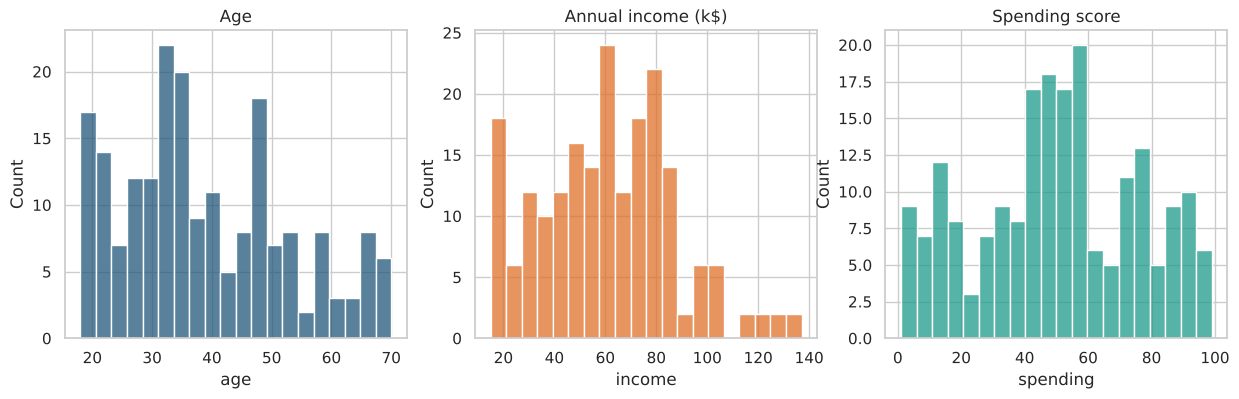

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["age"], bins=20, ax=ax[0], color="#22577A");      ax[0].set_title("Age")
sns.histplot(df["income"], bins=20, ax=ax[1], color="#E0702A");   ax[1].set_title("Annual income (k$)")
sns.histplot(df["spending"], bins=20, ax=ax[2], color="#1E9A8A"); ax[2].set_title("Spending score")
plt.show()

### 4.1 The most important chart: income vs spending

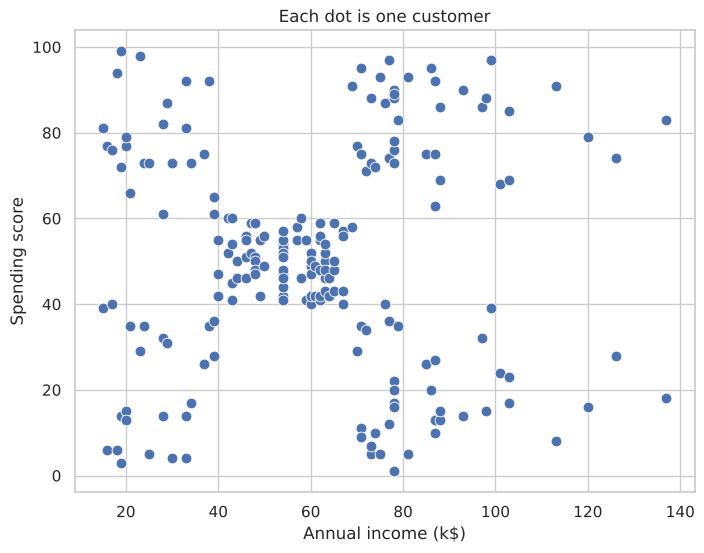

In [7]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="income", y="spending", s=60)
plt.title("Each dot is one customer")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score")
plt.show()

👀 **Look carefully.** Can you see **groups of dots** with your own eyes? Count them.
Most people see about **5 groups**: one in the middle and one in each corner.

Our eyes can do this with 2 columns. But with 10 or 50 columns we cannot draw a chart, so we need an **algorithm**: **K-means**.

## Step 5 · Choose the features and scale them

We group customers by **income** and **spending**, because that is what the marketing team cares about.

> 📘 **Why scale?** K-means measures the **distance** between customers. If one column has big numbers, it controls the distance.
> **StandardScaler** changes every column so its average is **0** and its spread is **1**, so both columns count equally.

In [8]:
X = df[["income", "spending"]]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)     # fit = learn average and spread, transform = apply them

print("Before scaling:", X.iloc[0].values)
print("After scaling :", X_scaled[0].round(2))

Before scaling: [15 39]
After scaling : [-1.74 -0.43]


> ℹ️ No train/test split today! In unsupervised learning there are **no answers to test against**. We use all 200 customers to find the groups.

## Step 6 · K-means: first try with 3 groups

> 📘 **K-means** (remember the theory class animation):
> 1. Choose **k** = how many groups you want.
> 2. Put **k centre points** at random places.
> 3. **Assign:** every customer joins the **nearest** centre.
> 4. **Update:** move each centre to the **middle** of its customers.
> 5. Repeat steps 3–4 until the centres stop moving.

> 📘 `n_init=10` means: try 10 different random starts and keep the best one.

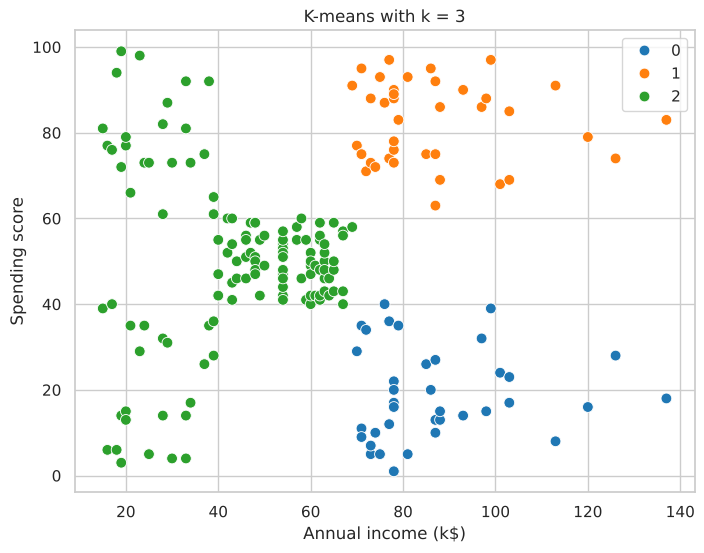

In [9]:
from sklearn.cluster import KMeans

kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42)
groups3 = kmeans3.fit_predict(X_scaled)      # learn the groups AND give each customer a group number

plt.figure(figsize=(8, 6))
sns.scatterplot(x=df["income"], y=df["spending"], hue=groups3, palette="tab10", s=60)
plt.title("K-means with k = 3")
plt.xlabel("Annual income (k$)"); plt.ylabel("Spending score")
plt.show()

It works, but 3 groups looks **too few**: the corner groups are joined together. So how do we choose the right **k**?

## Step 7 · How many groups? Two methods

### 7.1 The elbow method
> 📘 **Inertia:** how far customers are from their group centre, all added up. Small inertia = tight groups.
> More groups always means smaller inertia. We look for the **"elbow"**: the point where adding more groups **stops helping much**.

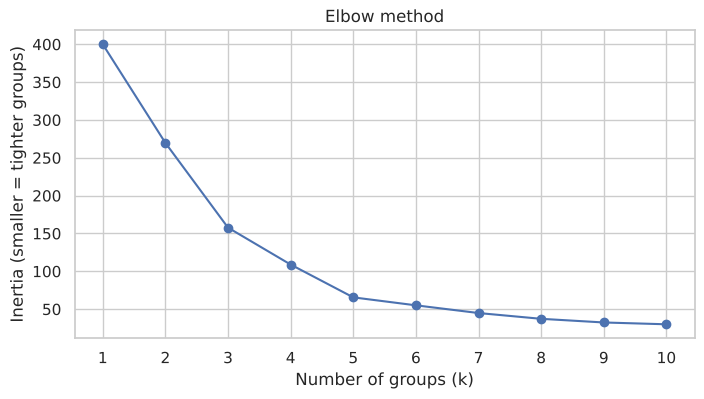

In [10]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.title("Elbow method")
plt.xlabel("Number of groups (k)")
plt.ylabel("Inertia (smaller = tighter groups)")
plt.show()

The line falls fast until **k = 5**, then slowly. The elbow is at **k = 5**. 💪

### 7.2 The silhouette score
> 📘 **Silhouette score** (from −1 to 1): how well each customer fits its **own** group compared with the **nearest other** group. **Higher = better groups.**

In [11]:
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    print(f"k = {k}  →  silhouette = {silhouette_score(X_scaled, labels):.3f}")

k = 2  →  silhouette = 0.321
k = 3  →  silhouette = 0.467
k = 4  →  silhouette = 0.494
k = 5  →  silhouette = 0.555
k = 6  →  silhouette = 0.540
k = 7  →  silhouette = 0.528
k = 8  →  silhouette = 0.455


Both methods agree: **k = 5** gives the best groups. ✅

## Step 8 · Train the final model with k = 5

In [12]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["group"] = kmeans.fit_predict(X_scaled)

df.head()

,gender,age,income,spending,group
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4


### 8.1 Draw the groups and their centres
The centres are in **scaled** numbers, so we use `scaler.inverse_transform` to turn them back into real income and spending.

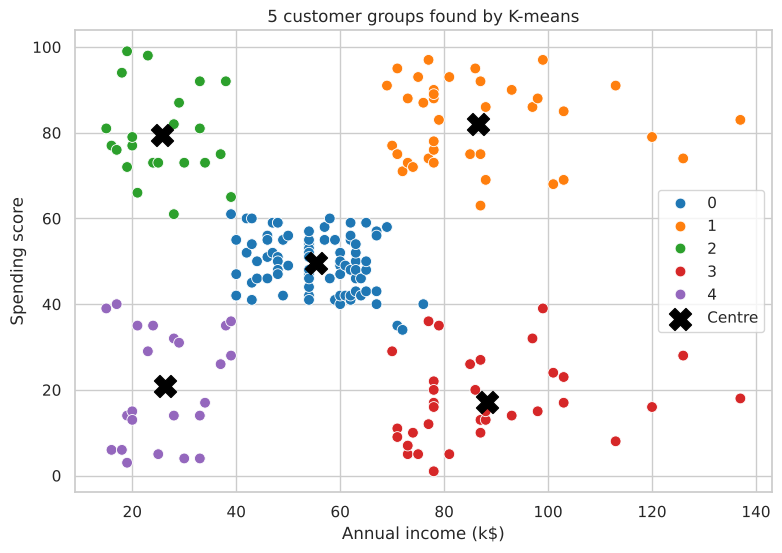

In [13]:
centres = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="income", y="spending", hue="group", palette="tab10", s=60)
plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=250, label="Centre")
plt.title("5 customer groups found by K-means")
plt.xlabel("Annual income (k$)"); plt.ylabel("Spending score")
plt.legend()
plt.show()

## Step 9 · Understand the groups (the most important step!)

The algorithm only gives **numbers** (group 0, 1, 2…). **People** must understand the groups and give them **names**.

In [14]:
profile = df.groupby("group")[["age", "income", "spending"]].mean().round(1)
profile["customers"] = df["group"].value_counts().sort_index()
profile

,age,income,spending,customers
group,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


Now we give each group a name, using simple rules:
- income **below 40** = low, **above 70** = high, otherwise medium
- spending **below 40** = low, **above 60** = high, otherwise medium

In [15]:
def level(value, low, high):
    if value < low:
        return "low"
    if value > high:
        return "high"
    return "medium"

group_names = {
    ("low", "low"):       "Budget savers",
    ("low", "high"):      "Young big spenders",
    ("medium", "medium"): "Average customers",
    ("high", "high"):     "VIP customers",
    ("high", "low"):      "Careful rich",
}
marketing_tips = {
    "Budget savers":      "Send discount coupons and 'buy 1 get 1' offers.",
    "Young big spenders": "Show trendy new products. Offer easy instalments.",
    "Average customers":  "Loyalty points and seasonal sales (Eid, 11.11).",
    "VIP customers":      "Premium membership, early access and personal service.",
    "Careful rich":       "Show quality and value: premium brands with long warranties.",
}

names, tips = {}, {}
for g, row in profile.iterrows():
    key = (level(row["income"], 40, 70), level(row["spending"], 40, 60))
    names[g] = group_names.get(key, "Other")
    tips[g] = marketing_tips.get(names[g], "")

profile["name"] = profile.index.map(names)
profile

,age,income,spending,customers,name
group,,,,,
0,42.7,55.3,49.5,81,Average customers
1,32.7,86.5,82.1,39,VIP customers
2,25.3,25.7,79.4,22,Young big spenders
3,41.1,88.2,17.1,35,Careful rich
4,45.2,26.3,20.9,23,Budget savers


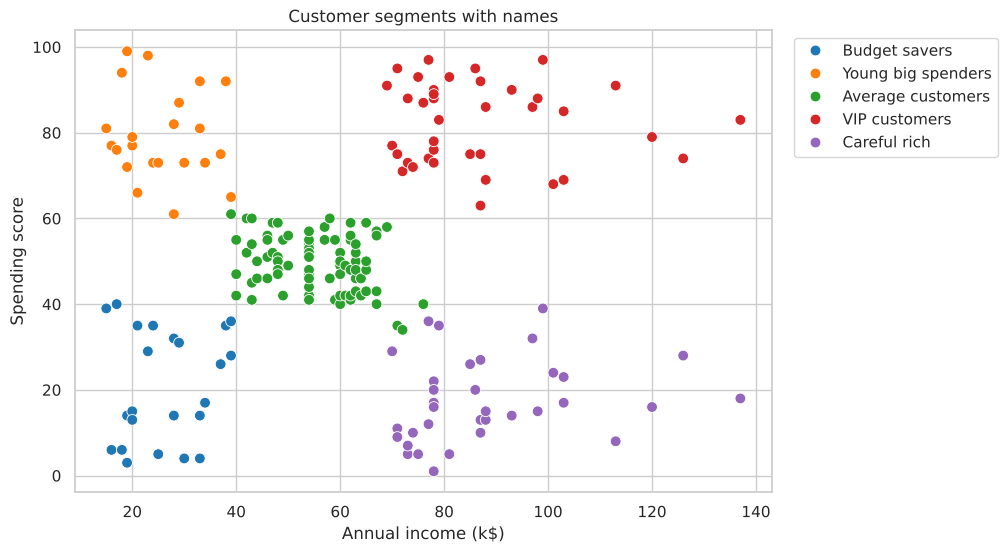

In [16]:
df["segment"] = df["group"].map(names)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="income", y="spending", hue="segment", palette="tab10", s=60)
plt.title("Customer segments with names")
plt.xlabel("Annual income (k$)"); plt.ylabel("Spending score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 9.1 What should the mall do? 💡

In [17]:
for g in sorted(names):
    print(f"Group {g} · {names[g]:<20} → {tips[g]}")

Group 0 · Average customers    → Loyalty points and seasonal sales (Eid, 11.11).
Group 1 · VIP customers        → Premium membership, early access and personal service.
Group 2 · Young big spenders   → Show trendy new products. Offer easy instalments.
Group 3 · Careful rich         → Show quality and value: premium brands with long warranties.
Group 4 · Budget savers        → Send discount coupons and 'buy 1 get 1' offers.


Did you notice? The **"Careful rich"** group has money but spends little. Converting even a few of them is a big win for the mall. This is the kind of **insight** that makes clustering valuable for a business.

✏️ **Your turn:** look at the `age` column in the profile table. Which group is the youngest? Does the name fit?

## Step 10 · Bonus 1: use 3 features and PCA

What if we also use **age**? Then each customer has **3 numbers** and we cannot draw a simple 2-D chart.

> 📘 **PCA (Principal Component Analysis):** squeezes many columns into **2 new columns** that keep most of the information, so we can **draw** the data.

The 2 PCA columns keep 78% of the information.


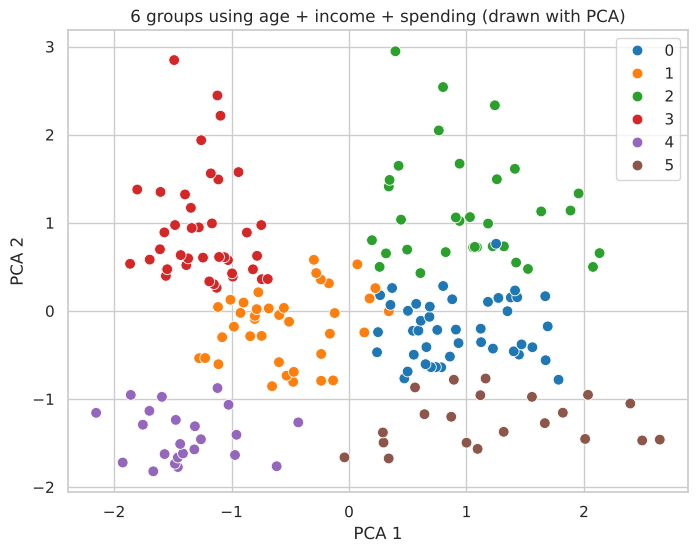

In [18]:
from sklearn.decomposition import PCA

X3 = StandardScaler().fit_transform(df[["age", "income", "spending"]])
groups_3d = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(X3)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X3)
print(f"The 2 PCA columns keep {pca.explained_variance_ratio_.sum():.0%} of the information.")

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=groups_3d, palette="tab10", s=60)
plt.title("6 groups using age + income + spending (drawn with PCA)")
plt.xlabel("PCA 1"); plt.ylabel("PCA 2")
plt.show()

## Step 11 · Bonus 2: hierarchical clustering (dendrogram)

> 📘 **Hierarchical clustering** joins the two closest customers, then the next closest… until everything is one big group. The tree it makes is called a **dendrogram**. Cut the tree with a line to choose the number of groups.
> We use **SciPy**, a science library that works together with NumPy.

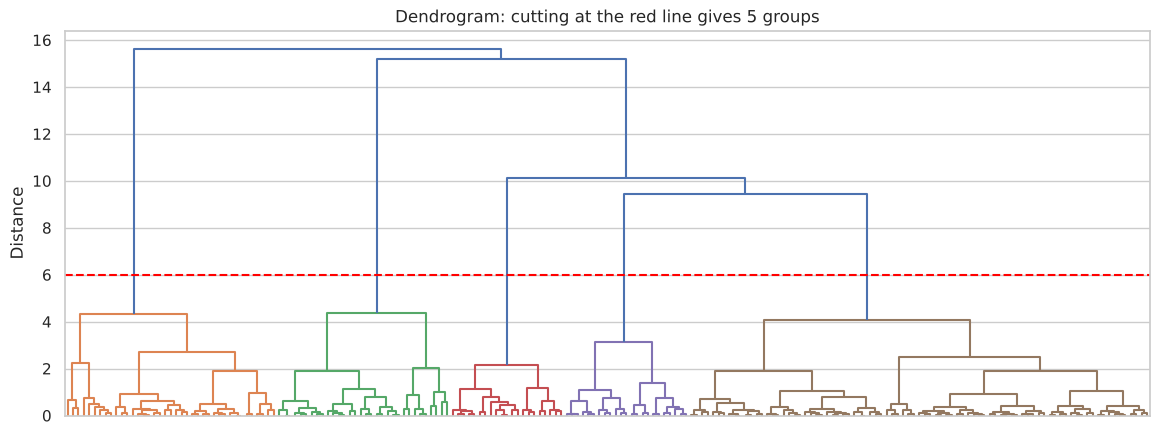

In [19]:
from scipy.cluster.hierarchy import dendrogram, linkage

tree = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(tree, no_labels=True, color_threshold=6)
plt.axhline(6, color="red", linestyle="--")
plt.title("Dendrogram: cutting at the red line gives 5 groups")
plt.ylabel("Distance")
plt.show()

The dendrogram **also** suggests **5 groups**. Two different methods agree, so we can trust our answer. ✅

## Step 12 · Save the model and test it live 🎉

We save **4 things together** in one file: the K-means model, the scaler, the group names and the marketing tips.
We also save the cleaned customer data, which the Streamlit app uses for its chart.
> 📘 **joblib** saves Python objects into a file.

In [20]:
import joblib

joblib.dump({"model": kmeans, "scaler": scaler, "names": names, "tips": tips}, "segment_model.pkl")
df[["gender", "age", "income", "spending"]].to_csv("Mall_Customers_clean.csv", index=False)
print("Saved segment_model.pkl and Mall_Customers_clean.csv ✅")

Saved segment_model.pkl and Mall_Customers_clean.csv ✅


### 12.1 A function that finds the group of any customer

In [21]:
saved = joblib.load("segment_model.pkl")

def find_segment(income, spending):
    new_customer = pd.DataFrame({"income": [income], "spending": [spending]})
    g = int(saved["model"].predict(saved["scaler"].transform(new_customer))[0])   # scale first, then predict
    print(f"🛍️ Group {g}: {saved['names'][g]}")
    print(f"💡 Idea: {saved['tips'][g]}")
    return g

find_segment(income=120, spending=90);

🛍️ Group 1: VIP customers
💡 Idea: Premium membership, early access and personal service.


In [22]:
find_segment(income=110, spending=15);

🛍️ Group 3: Careful rich
💡 Idea: Show quality and value: premium brands with long warranties.


### 12.2 🎤 Live test: type a customer's details!
Run the cell and answer the two questions.

In [ ]:
income = float(input("Annual income in thousand $ (e.g. 60): "))
spending = float(input("Spending score from 1 to 100 (e.g. 50): "))
print()
find_segment(income, spending);

---
## Step 13 · Make a web app with Streamlit 🌐

> 📘 **Streamlit** turns a Python script into a web page. `%%writefile app.py` saves the cell into a file.

### 13.1 Write `app.py`

In [23]:
%%writefile app.py
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="Mall Customer Segments", page_icon="🛍️")


# 1. Load the saved model, scaler, segment names and the customer data (only once)
@st.cache_resource
def load_everything():
    saved = joblib.load("segment_model.pkl")
    customers = pd.read_csv("Mall_Customers_clean.csv")
    return saved, customers

saved, customers = load_everything()
model, scaler, names, tips = saved["model"], saved["scaler"], saved["names"], saved["tips"]

# 2. Page title
st.title("🛍️ Which customer group is this?")
st.write("Move the sliders to describe a customer. The K-means model puts them in one of **5 groups**.")

# 3. Inputs
income = st.slider("Annual income (thousand $)", 10, 150, 60)
spending = st.slider("Spending score (1 = spends very little, 100 = spends a lot)", 1, 100, 50)

# 4. Predict the group: scale the numbers the same way as in training, then ask the model
new_customer = pd.DataFrame({"income": [income], "spending": [spending]})
group = int(model.predict(scaler.transform(new_customer))[0])

st.subheader(f"Group {group}: {names[group]}")
st.info(f"💡 Marketing idea: {tips[group]}")

# 5. Chart: all customers coloured by group, plus the new customer as a big star
all_groups = model.predict(scaler.transform(customers[["income", "spending"]]))
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(customers["income"], customers["spending"], c=all_groups, cmap="tab10", vmin=0, vmax=9, s=40, alpha=0.7)
ax.scatter(income, spending, marker="*", s=600, c="black", edgecolors="yellow", linewidths=1.5, label="This customer")
ax.set_xlabel("Annual income (thousand $)")
ax.set_ylabel("Spending score")
ax.legend(loc="upper center")
st.pyplot(fig)

# 6. Short table of the groups
st.write("**The 5 groups**")
st.table(pd.DataFrame({"Group": list(names.keys()), "Name": list(names.values())}).set_index("Group"))

Writing app.py


**How the app works:**
1. `load_everything()` opens the saved model and the customer data **once** (`@st.cache_resource`).
2. Two **sliders** set income and spending.
3. The new customer is **scaled with the same scaler**, then K-means finds the nearest group.
4. The app shows the **group name**, a **marketing idea**, and a **chart** with the new customer as a ⭐.

### 13.2 Write `requirements.txt`

In [24]:
import sklearn

with open("requirements.txt", "w") as f:
    f.write(f"""streamlit
scikit-learn=={sklearn.__version__}
pandas
matplotlib
joblib
""")
print(open("requirements.txt").read())

streamlit
scikit-learn==1.9.1
pandas
matplotlib
joblib



### 13.3 Run the app on your computer (Jupyter / Anaconda users)
Open **Anaconda Prompt**, go to this notebook's folder with `cd`, then run:
```
pip install streamlit
streamlit run app.py
```
The app opens at **http://localhost:8501**. Stop it with **Ctrl + C**.

### 13.4 Colab users: download the 4 files

In [25]:
try:
    from google.colab import files       # only works inside Google Colab
    for name in ["app.py", "requirements.txt", "segment_model.pkl", "Mall_Customers_clean.csv"]:
        files.download(name)
except ImportError:
    print("Not in Colab: the 4 files are already saved in this notebook's folder ✅")

Not in Colab: the 4 files are already saved in this notebook's folder ✅


## Step 14 · Put it live: GitHub + Streamlit Community Cloud 🚀
You need **4 files**: `app.py`, `requirements.txt`, `segment_model.pkl`, `Mall_Customers_clean.csv`.

### 14.1 Push to GitHub
1. On **[github.com](https://github.com)** click **+ → New repository**, name it `customer-segments-app`, choose **Public**, tick **Add a README file**, then click **Create repository**.
2. **Easiest:** click **Add file → Upload files**, drag in the 4 files, then click **Commit changes**.
3. **Or with Git commands**, in the folder with the 4 files (change `YOUR-USERNAME`):
```bash
git init
git add app.py requirements.txt segment_model.pkl Mall_Customers_clean.csv
git commit -m "Customer segmentation app"
git branch -M main
git remote add origin https://github.com/YOUR-USERNAME/customer-segments-app.git
git pull origin main --allow-unrelated-histories
git push -u origin main
```

### 14.2 Deploy
1. Go to **[share.streamlit.io](https://share.streamlit.io)** → **Continue with GitHub**.
2. **Create app** → **Deploy a public app from GitHub**.
3. Repository: `YOUR-USERNAME/customer-segments-app` · Branch: `main` · Main file: `app.py`.
4. **Advanced settings** → choose the same **Python version** you trained with (Colab: **3.12**).
5. Click **Deploy** and wait 2–5 minutes. 🎉

| Problem | Fix |
|---|---|
| `FileNotFoundError` | one of the 4 files is missing, or is in a sub-folder. Put all of them next to `app.py`. |
| Error while loading the model | the `scikit-learn` version in `requirements.txt` must match your notebook. Run Step 13.2 again. |
| App is sleeping | free apps sleep. Click **"Yes, get this app back up"**. |

## 🎉 Well done!

You found **hidden customer groups without any labels**, named them, turned them into **business ideas**, and built a **web app**.

| | Supervised | Unsupervised |
|---|---|---|
| Has answers (y)? | Yes | **No** |
| Main question | "What is the answer?" | **"What groups exist?"** |
| How we judge it | accuracy, MAE, recall… | **elbow, silhouette, and does it make business sense?** |

### ✏️ Practice tasks
1. Try **k = 4** and **k = 6** in Step 8. Do the group names still make sense?
2. Cluster using **age and spending** instead. What groups do you find? Name them.
3. Compare the **gender** split inside each segment with `pd.crosstab(df["segment"], df["gender"])`.
4. Try **DBSCAN** from `sklearn.cluster`: `DBSCAN(eps=0.5, min_samples=5).fit_predict(X_scaled)`. Points labelled **−1** are "noise". Which customers are they?
5. Add a **third slider for age** to the Streamlit app (you must retrain with 3 features).